# AI-Based Customer Spending Prediction

## Project Overview
This project develops a beginner-friendly machine learning classification system to predict whether a customer belongs to a Low, Medium, or High spending category.

## Objective
To understand and implement a complete machine learning workflow involving data cleaning, exploratory data analysis, feature engineering, preprocessing, model training, evaluation, and prediction.

## Dataset
Mall Customer Segmentation Dataset.

## Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Jupyter Notebook

## Problem Type
Supervised Machine Learning – Multiclass Classification.

In [14]:
import os
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

BASE_DIR = os.path.abspath(os.path.join(os.getcwd(), ".."))

DATA_DIR = os.path.join(BASE_DIR, "data")
MODEL_DIR = os.path.join(BASE_DIR, "models")
PLOT_DIR = os.path.join(BASE_DIR, "visualizations")
REPORT_DIR = os.path.join(BASE_DIR, "reports")

for folder in [MODEL_DIR, PLOT_DIR, REPORT_DIR]:
    os.makedirs(folder, exist_ok=True)

print("Libraries imported successfully!")

Libraries imported successfully!


In [15]:
BASE_DIR = r"D:\Veda_tech_internship\day_32"

DATA_DIR = os.path.join(BASE_DIR, "data")
MODEL_DIR = os.path.join(BASE_DIR, "models")
PLOT_DIR = os.path.join(BASE_DIR, "visualizations")
REPORT_DIR = os.path.join(BASE_DIR, "reports")

for folder in [MODEL_DIR, PLOT_DIR, REPORT_DIR]:
    os.makedirs(folder, exist_ok=True)

print("Project directory:", BASE_DIR)
print("Dataset directory:", DATA_DIR)

Project directory: D:\Veda_tech_internship\day_32
Dataset directory: D:\Veda_tech_internship\day_32\data


In [16]:
file_path = os.path.join(DATA_DIR, "Mall_Customers.csv")

print("File exists:", os.path.exists(file_path))

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

File exists: True
Dataset loaded successfully!
Dataset shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [17]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,200.0,NaN,NaN,NaN,100.5,57.879185,1.0,50.75,100.5,150.25,200.0
Gender,200,2,Female,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,200.0,NaN,NaN,NaN,38.85,13.969007,18.0,28.75,36.0,49.0,70.0
Annual Income (k$),200.0,NaN,NaN,NaN,60.56,26.264721,15.0,41.5,61.5,78.0,137.0
Spending Score (1-100),200.0,NaN,NaN,NaN,50.2,25.823522,1.0,34.75,50.0,73.0,99.0



Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate records: 0


In [18]:
df.columns = df.columns.str.strip()

df = df.rename(columns={
    "Annual Income (k$)": "Annual_Income",
    "Spending Score (1-100)": "Spending_Score"
})

required_columns = [
    "CustomerID",
    "Gender",
    "Age",
    "Annual_Income",
    "Spending_Score"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

df = df.drop_duplicates().copy()

df["Gender"] = df["Gender"].astype("string").str.strip()

for col in ["Age", "Annual_Income", "Spending_Score"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Cleaned dataset shape:", df.shape)
display(df.head())

Cleaned dataset shape: (200, 5)


,CustomerID,Gender,Age,Annual_Income,Spending_Score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [19]:
for col in ["Age", "Annual_Income", "Spending_Score"]:
    df[col] = df[col].fillna(df[col].median())

df["Gender"] = df["Gender"].fillna(
    df["Gender"].mode()[0]
)

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
CustomerID        0
Gender            0
Age               0
Annual_Income     0
Spending_Score    0
dtype: int64


## 3. Feature Engineering

The original Spending Score is converted into a categorical target variable.

- Score 1–39: Low Spending
- Score 40–60: Medium Spending
- Score 61–100: High Spending

The original Spending Score will not be used as an input feature because it directly determines the target category.

In [20]:
df["Spending_Category"] = pd.cut(
    df["Spending_Score"],
    bins=[0, 39, 60, 100],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

print("Spending categories created!")
print(df["Spending_Category"].value_counts())

display(df[
    ["CustomerID", "Spending_Score", "Spending_Category"]
].head(10))

Spending categories created!
Spending_Category
Medium    79
High      62
Low       59
Name: count, dtype: int64


,CustomerID,Spending_Score,Spending_Category
0,1,39,Low
1,2,81,High
2,3,6,Low
3,4,77,High
4,5,40,Medium
5,6,76,High
6,7,6,Low
7,8,94,High
8,9,3,Low
9,10,72,High


In [21]:
df["Spending_Category"] = pd.cut(
    df["Spending_Score"],
    bins=[0, 39, 60, 100],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

print("Spending categories created!")
print(df["Spending_Category"].value_counts())

display(df[
    ["CustomerID", "Spending_Score", "Spending_Category"]
].head(10))

Spending categories created!
Spending_Category
Medium    79
High      62
Low       59
Name: count, dtype: int64


,CustomerID,Spending_Score,Spending_Category
0,1,39,Low
1,2,81,High
2,3,6,Low
3,4,77,High
4,5,40,Medium
5,6,76,High
6,7,6,Low
7,8,94,High
8,9,3,Low
9,10,72,High


In [22]:
print("Invalid target values:", df["Spending_Category"].isna().sum())

print("\nFinal dataset information:")
print(df.info())

print("\nCategory distribution:")
display(df["Spending_Category"].value_counts())

Invalid target values: 0

Final dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   CustomerID         200 non-null    int64   
 1   Gender             200 non-null    string  
 2   Age                200 non-null    int64   
 3   Annual_Income      200 non-null    int64   
 4   Spending_Score     200 non-null    int64   
 5   Spending_Category  200 non-null    category
dtypes: category(1), int64(4), string(1)
memory usage: 8.3 KB
None

Category distribution:


Spending_Category
Medium    79
High      62
Low       59
Name: count, dtype: int64

## 4. Exploratory Data Analysis (EDA)

EDA is performed to understand customer characteristics, spending patterns, and relationships between different variables.

At least five visualizations are generated to identify meaningful patterns.

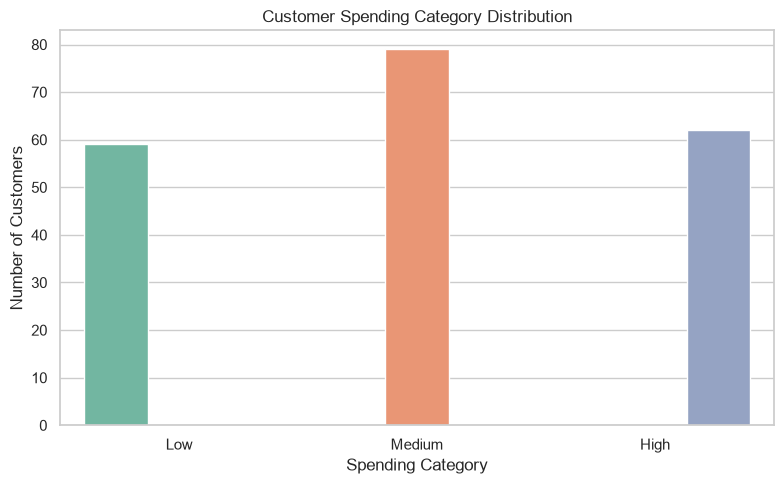

In [23]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Spending_Category",
    hue="Spending_Category",
    palette="Set2",
    legend=False
)

plt.title("Customer Spending Category Distribution")
plt.xlabel("Spending Category")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "01_spending_category_distribution.png"),
    dpi=300
)
plt.show()

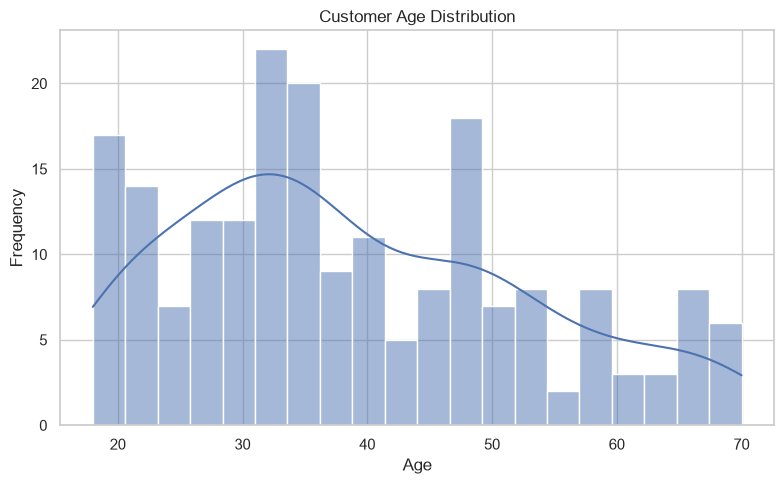

In [24]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Age",
    bins=20,
    kde=True
)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "02_age_distribution.png"),
    dpi=300
)
plt.show()

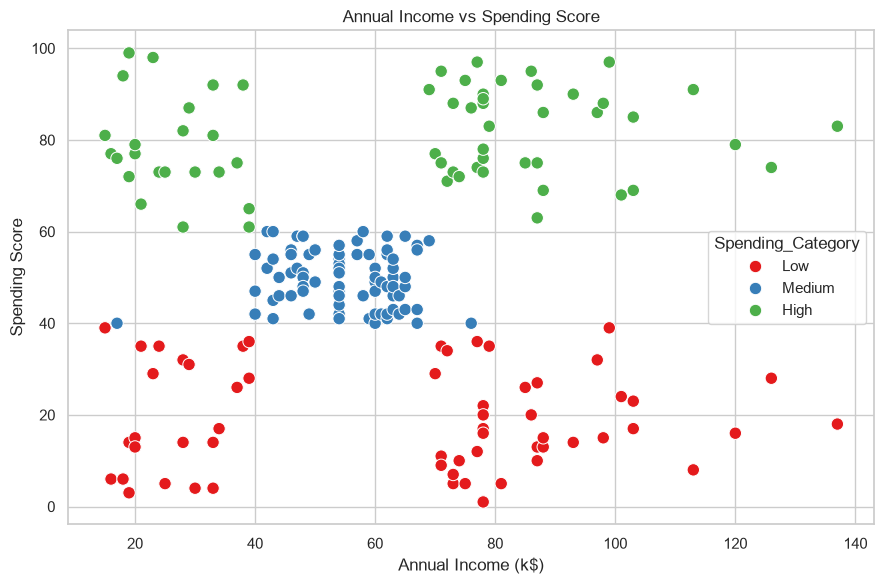

In [25]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Annual_Income",
    y="Spending_Score",
    hue="Spending_Category",
    palette="Set1",
    s=80
)

plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "03_income_vs_spending.png"),
    dpi=300
)
plt.show()

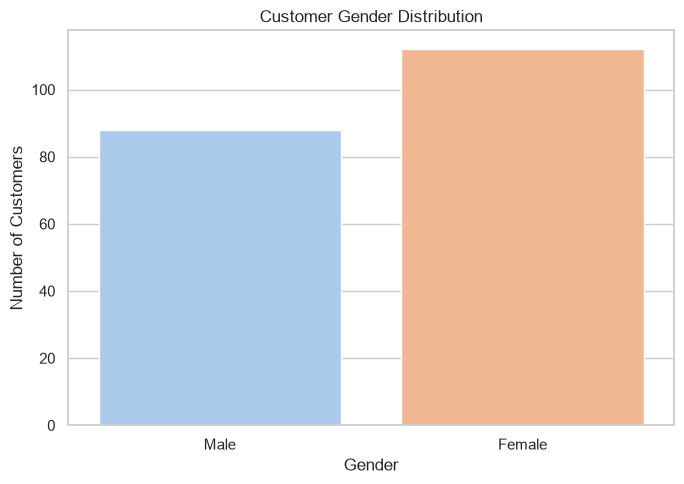

In [26]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Gender",
    hue="Gender",
    palette="pastel",
    legend=False
)

plt.title("Customer Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "04_gender_distribution.png"),
    dpi=300
)
plt.show()

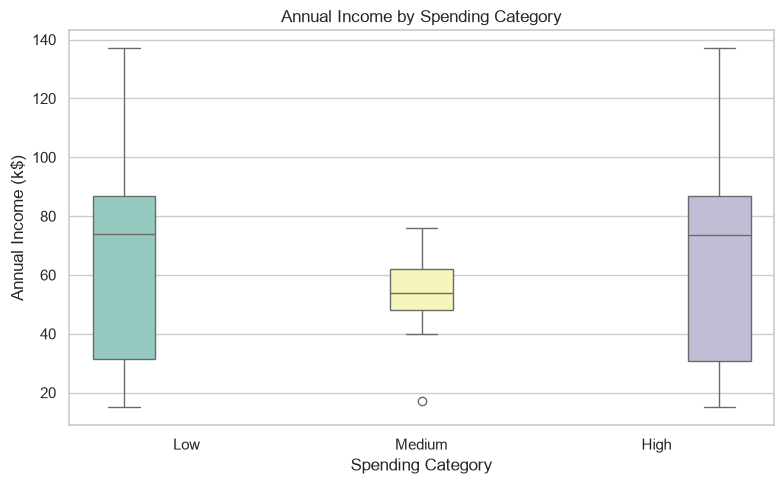

In [27]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Spending_Category",
    y="Annual_Income",
    hue="Spending_Category",
    palette="Set3",
    legend=False
)

plt.title("Annual Income by Spending Category")
plt.xlabel("Spending Category")
plt.ylabel("Annual Income (k$)")
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "05_income_by_category.png"),
    dpi=300
)
plt.show()

## 5. Feature Selection and Preprocessing

The input features are:
- Gender
- Age
- Annual Income

The target variable is:
- Spending Category

CustomerID is excluded because it is only an identifier.
Spending Score is excluded because it was used to create the target variable.

Categorical data will be encoded using OneHotEncoder.
Numerical data will be scaled using StandardScaler.
Missing values will be handled through SimpleImputer.

In [28]:
feature_columns = ["Gender", "Age", "Annual_Income"]
target_column = "Spending_Category"

X = df[feature_columns].copy()
y = df[target_column].copy()

print("Input features (X):")
display(X.head())

print("\nTarget variable (y):")
display(y.head())

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Input features (X):


,Gender,Age,Annual_Income
0,Male,19,15
1,Male,21,15
2,Female,20,16
3,Female,23,16
4,Female,31,17



Target variable (y):


0       Low
1      High
2       Low
3      High
4    Medium
Name: Spending_Category, dtype: category
Categories (3, str): ['Low' < 'Medium' < 'High']


X shape: (200, 3)
y shape: (200,)


In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 160
Testing records: 40


In [31]:
numeric_features = ["Age", "Annual_Income"]
categorical_features = ["Gender"]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


## 6. Model Training

Two classification algorithms are selected:

1. Logistic Regression
2. Random Forest Classifier

Both models will use the same preprocessing pipeline and training data.
Their performance will be compared using accuracy, precision, recall, and F1-score.

In [32]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    )
}

trained_models = {}
results = []

for model_name, classifier in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    trained_models[model_name] = pipeline

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        )
    })

    print(f"\n{model_name} training completed!")

results_df = pd.DataFrame(results)

display(
    results_df.sort_values("F1 Score", ascending=False)
)


Logistic Regression training completed!

Random Forest training completed!


,Model,Accuracy,Precision,Recall,F1 Score
1,Random Forest,0.900,0.900000,0.900,0.900000
0,Logistic Regression,0.575,0.563815,0.575,0.558021


## 7. Model Evaluation

The trained models are compared using four performance metrics:

- Accuracy: Overall proportion of correct predictions.
- Precision: Proportion of predicted positives that are correct.
- Recall: Proportion of actual positives correctly identified.
- F1-score: Harmonic mean of precision and recall.

The weighted average is used because the number of records in each class may differ.

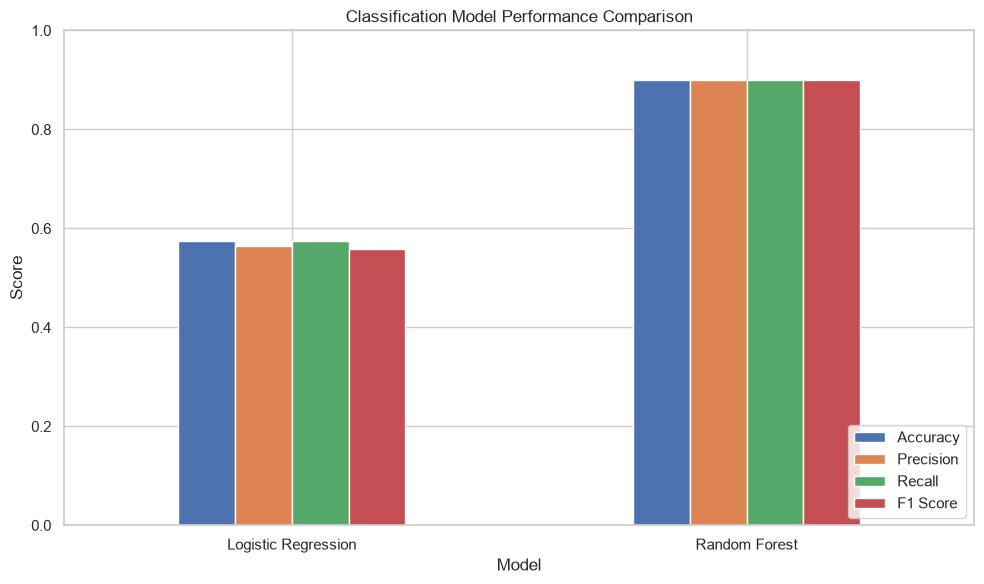

In [33]:
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Classification Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [34]:
best_model_name = results_df.sort_values(
    "F1 Score",
    ascending=False
).iloc[0]["Model"]

best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_test)

print("Best Model:", best_model_name)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        best_predictions,
        zero_division=0
    )
)

Best Model: Random Forest

Classification Report:
              precision    recall  f1-score   support

        High       0.83      0.83      0.83        12
         Low       0.83      0.83      0.83        12
      Medium       1.00      1.00      1.00        16

    accuracy                           0.90        40
   macro avg       0.89      0.89      0.89        40
weighted avg       0.90      0.90      0.90        40



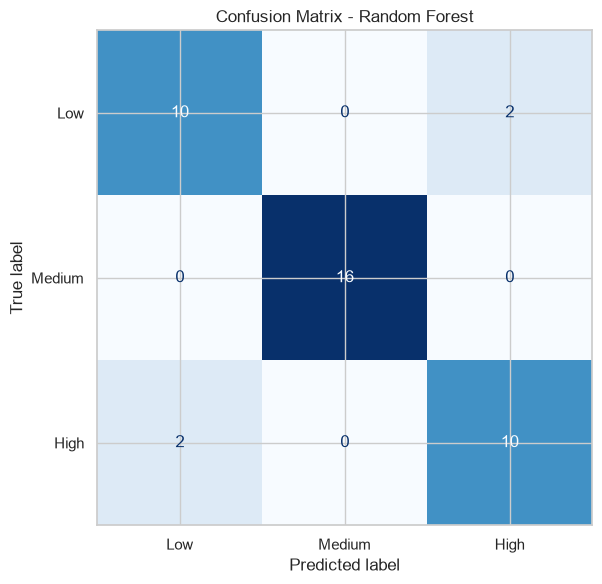

In [35]:
cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=["Low", "Medium", "High"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Medium", "High"]
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    cmap="Blues",
    ax=ax,
    colorbar=False
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "06_confusion_matrix.png"),
    dpi=300
)

plt.show()

## 8. Feature Importance and Model Interpretation

Feature importance helps us understand which input variables contribute most to the Random Forest model's predictions.

The feature importance results are interpreted as model-specific associations, not proof of causation.

,Feature,Importance
1,num__Annual_Income,0.589701
0,num__Age,0.386256
2,cat__Gender_Female,0.012713
3,cat__Gender_Male,0.011329


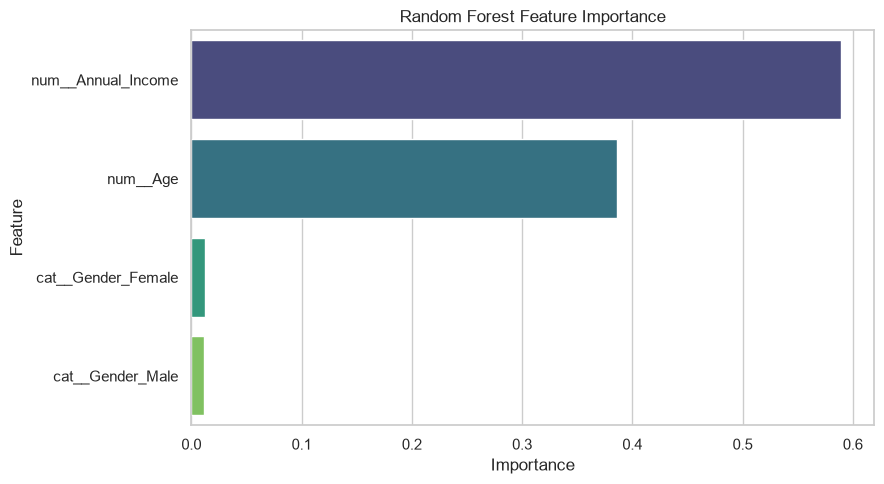

In [36]:
rf_pipeline = trained_models["Random Forest"]

rf_classifier = rf_pipeline.named_steps["classifier"]

feature_names = (
    rf_pipeline.named_steps["preprocessor"].get_feature_names_out()
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 9. Customer Spending Prediction

The best-performing model is used to predict the spending category of a new customer.

The prediction function accepts customer demographic and income information and returns a predicted category.

In [38]:
def predict_customer_spending(gender, age, annual_income):

    new_customer = pd.DataFrame({
        "Gender": [gender],
        "Age": [age],
        "Annual_Income": [annual_income]
    })

    prediction = best_model.predict(new_customer)

    return prediction[0]


sample_prediction = predict_customer_spending(
    gender="Male",
    age=30,
    annual_income=60
)

print("Sample Customer Spending Category:", sample_prediction)

Sample Customer Spending Category: Medium


In [39]:
model_path = os.path.join(
    MODEL_DIR,
    "best_customer_spending_model.joblib"
)

joblib.dump(best_model, model_path)

cleaned_path = os.path.join(
    DATA_DIR,
    "cleaned_customer_data.csv"
)

df.to_csv(cleaned_path, index=False)

print("Model saved:", model_path)
print("Cleaned dataset saved:", cleaned_path)

Model saved: D:\Veda_tech_internship\day_32\models\best_customer_spending_model.joblib
Cleaned dataset saved: D:\Veda_tech_internship\day_32\data\cleaned_customer_data.csv


## 10. Final Conclusion

This project demonstrates an end-to-end supervised machine learning classification workflow.

The customer dataset was cleaned and explored through visualizations. A spending category target was engineered using the original spending score. Two classification models, Logistic Regression and Random Forest, were trained and compared.

The best-performing model was selected using weighted F1-score. A confusion matrix, feature importance analysis, and sample prediction function were also implemented.

This project provides practical understanding of how machine learning can support customer segmentation and business decision-making.